# Matched fleet handling study

## Results at a glance

The executed cells below identify the longest braking distance, the least steering response, and the ground-support/reset outcomes across **all 13 cars, five scenarios, two repetitions: 130 production runs**. The frozen comparison is in `comparison.csv`; each run and its file hashes are in `evidence.json`.

These are simulation measurements using shared arcade tuning. Two repetitions test reproducibility on this machine; they do not estimate population uncertainty or real vehicle performance.

## Context and methods

All scenarios use the production command bus, vehicle/Rapier systems, city colliders, prepared assets and 120 Hz step, with rendering disabled. Initial pose: `[-150, 0.62, 458]`, heading +X along the clear perimeter road. Inputs begin after two seconds of settling relative to scenario readiness. No physics or car parameters are changed.

- **Braking:** six seconds full throttle, then full brake. Distance/time end at the first completed state at or below **1 m/s**, before the game's automatic reverse. One deliberate reset follows at tick 1680; its recovery is checked one second later.
- **Turning:** full throttle throughout; steer ±0.5 after three seconds (two-second turn) and six seconds (1.5-second turn). Smaller heading change means less response to this input, not automatically worse stability.
- **Support:** four raycast contacts, zero-contact ticks, loaded wheels (>1 N), tilt, and slip in each maneuver. A contact is not proof of equal tire load.
- **Resets:** requested recovery is counted separately from unrequested resets. No car selections occur.
- **Boundaries:** input is consumed before the fixed step; positions/velocities use completed-state events. Orientation/contact information uses the explicitly matched pre-step physics rows. The action window is [action tick, end tick).

Source code: `tools/handling_protocol.py`, `tools/run_handling_study.py`, `tools/handling_metrics.py`, `tools/analyze_handling_study.py`. Run paths resolve relative to the repository root. Raw traces remain under `artifacts/handling-study-20261023/`.

### Key assumptions

This smooth-road, full-throttle/half-steer protocol tests ordinary handling and a faster corner entry. It does not establish behavior over curbs, off-road, in handbrake slides, or with other tuning. The 350Z's intact assembly pilot projects baseline mass/inertia; other fleet cars use baseline mass properties directly. All scenarios passed the same measured input, asset, health and obstacle-clearance audits.

### 1. Load the frozen evidence

In [1]:
from pathlib import Path
import json, math, statistics, hashlib
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "Cargo.toml").exists())
OUT = ROOT / "docs/verification/handling-study"
evidence = json.loads((OUT / "evidence.json").read_text())
rows = evidence["aggregate"]
runs = evidence["runs"]
assert evidence["complete_runs"] == 130
assert len({r["car"] for r in runs}) == 13
assert all(r["n"] == 2 for r in rows)
assert len(rows) == 65
by = {(r["car"], r["case"]): r for r in rows}
order = sorted({r["car"] for r in rows}, key=lambda car: -by[car,"brake"]["near_stop_m"])

def read_jsonl(path):
    return [json.loads(line) for line in path.read_text().splitlines() if line.strip()]

worst_brake = order[0]
best_brake = order[-1]
low_response = min(order, key=lambda car: statistics.mean(by[car,c]["turn_deg"] for c in ["turn-left","turn-right"]))
fast_response = min(order, key=lambda car: statistics.mean(by[car,c]["turn_deg"] for c in ["fast-left","fast-right"]))
summary = (f"**Longest braking:** {worst_brake}, {by[worst_brake,'brake']['near_stop_m']:.2f} m / "
           f"{by[worst_brake,'brake']['near_stop_s']:.2f} s to 1 m/s; shortest: {best_brake}, "
           f"{by[best_brake,'brake']['near_stop_m']:.2f} m.\n\n"
           f"**Least heading response:** {low_response} in the lower-speed turns; "
           f"{fast_response} in the faster turns.\n\n"
           f"**Ground support:** {min(r['four_contact_pct'] for r in rows):.1f}% four-contact ticks minimum across cases. "
           f"**Unrequested resets:** {sum(r['unexpected_resets'] for r in runs)}. "
           f"Requested recoveries: {sum(r['requested_resets'] for r in runs)}. "
           f"**Identical numeric repeats:** {evidence['identical_repeat_groups']}/65 car/case pairs.")
display(Markdown(summary))

**Longest braking:** redline-911, 39.28 m / 2.85 s to 1 m/s; shortest: gt4-m3, 38.09 m.

**Least heading response:** mc3-supra in the lower-speed turns; gt-rx7 in the faster turns.

**Ground support:** 100.0% four-contact ticks minimum across cases. **Unrequested resets:** 0. Requested recoveries: 26. **Identical numeric repeats:** 53/65 car/case pairs.

### 2. Independently recompute the consequential metrics from raw traces

In [2]:
# This cell intentionally does not import the metric helper used to build the CSV.
max_distance_error = 0.0
max_yaw_error = 0.0
support_ticks = 0
for run in runs:
    directory = ROOT / run["run"]
    ready = run["ready_tick"]
    events = read_jsonl(directory / "events.jsonl")
    completed = {e["tick"]-ready: e["fields"] for e in events if e["kind"] == "simulation.completed"}
    physics = {p["tick"]-ready: p for p in read_jsonl(directory / "physics.jsonl")}
    start = 960 if run["case"] in ["brake","fast-left","fast-right"] else 600
    if run["case"] == "brake":
        stop = next(t for t in range(start,1440) if np.linalg.norm(np.array(completed[t]["linear_velocity"])[[0,2]]) <= 1)
        positions = np.array([completed[t]["position"] for t in range(start-1,stop+1)])[:,[0,2]]
        distance = np.linalg.norm(np.diff(positions,axis=0),axis=1).sum()
        max_distance_error = max(max_distance_error, abs(distance-run["near_stop_m"]))
        assert abs((stop-start+1)/120-run["near_stop_s"]) < 1e-12
        end = stop+1
    else:
        end = 1140 if run["case"].startswith("fast") else 840
        quats = np.array([physics[t]["rotation"] for t in range(start,end+1)])
        x,y,z,w = quats.T
        angles = np.unwrap(np.arctan2(-2*(x*z+y*w),1-2*(x*x+y*y)))
        yaw = np.degrees(angles[-1]-angles[0]) * (-1 if run["case"].endswith("left") else 1)
        max_yaw_error = max(max_yaw_error,abs(yaw-run["turn_deg"]))
    contacts = [physics[t]["grounded"] for t in range(start,end)]
    assert abs(100*contacts.count(4)/len(contacts)-run["four_contact_pct"]) < 1e-12
    assert len([e for e in events if e["kind"]=="vehicle.reset"]) == run["requested_resets"]+run["unexpected_resets"]
    support_ticks += len(contacts)
assert max_distance_error < 1e-9
assert max_yaw_error < 1e-9
print(f"Independent recomputation: {len(runs)} runs, {support_ticks:,} support ticks; "
      f"max distance difference {max_distance_error:.2g} m, max yaw difference {max_yaw_error:.2g} degrees.")

Independent recomputation: 130 runs, 30,574 support ticks; max distance difference 0 m, max yaw difference 1.4e-14 degrees.


### 3. Compare all cars on the same scales

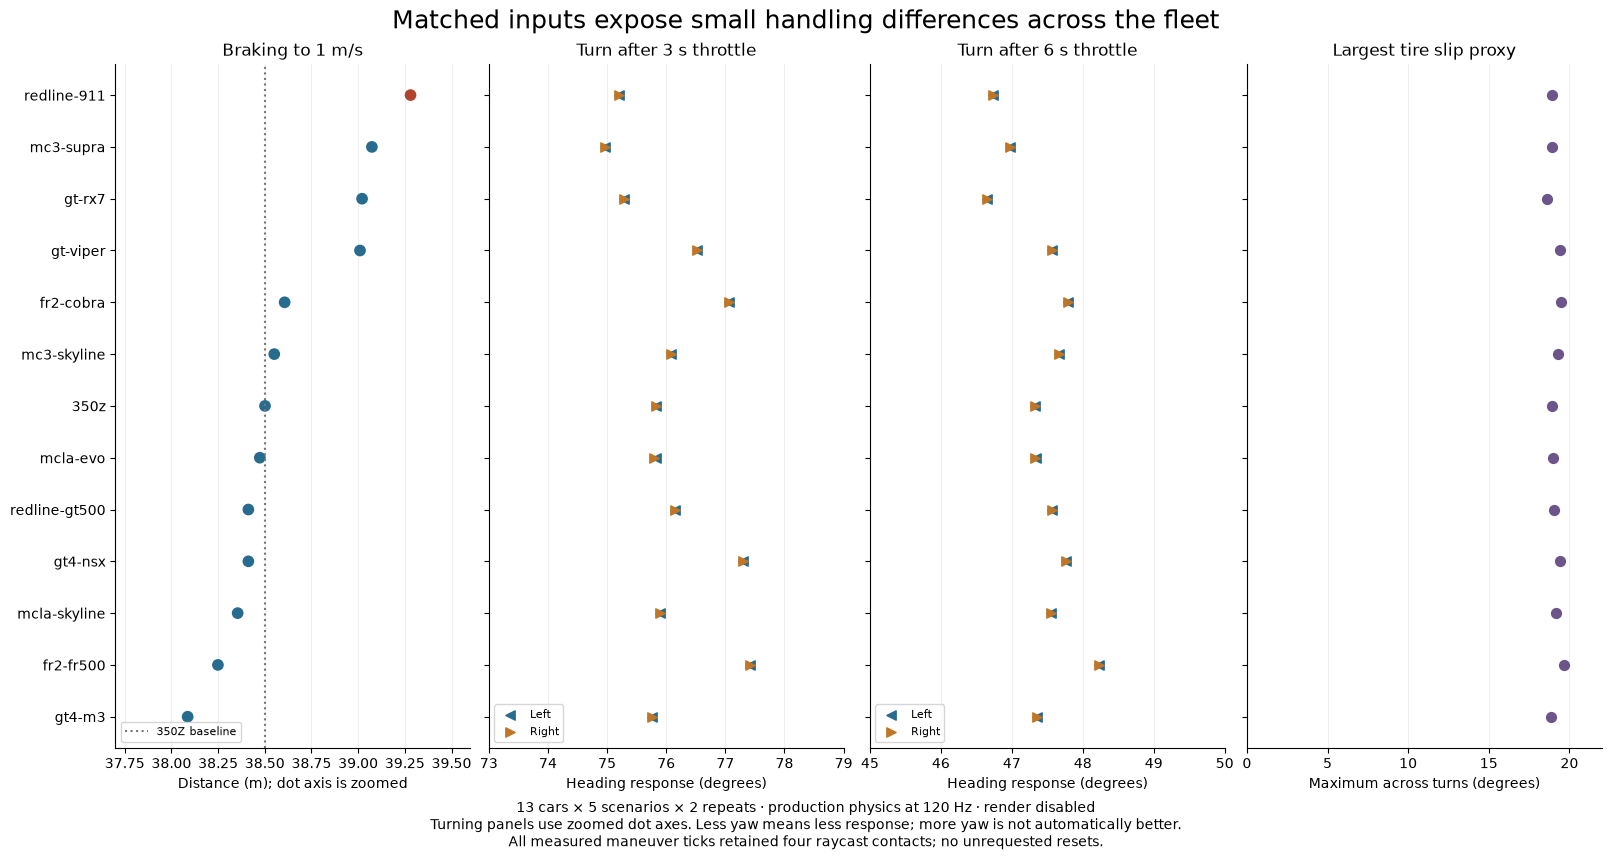

In [3]:
plt.rcParams.update({"font.size":10, "axes.spines.top":False, "axes.spines.right":False,
                     "figure.facecolor":"white", "axes.facecolor":"white"})
fig, axes = plt.subplots(1,4,figsize=(16,8.5),sharey=True,layout="constrained")
y = np.arange(len(order))
colors = ["#b2442e" if car == worst_brake else "#276b8e" for car in order]
axes[0].scatter([by[car,"brake"]["near_stop_m"] for car in order], y, c=colors, s=55)
axes[0].axvline(by["350z","brake"]["near_stop_m"],color="#777777",linestyle=":",label="350Z baseline")
axes[0].set(title="Braking to 1 m/s",xlabel="Distance (m); dot axis is zoomed",xlim=(37.7,39.6))
axes[0].legend(loc="lower left",fontsize=8)
for ax,cases,title in [(axes[1],["turn-left","turn-right"],"Turn after 3 s throttle"),
                       (axes[2],["fast-left","fast-right"],"Turn after 6 s throttle")]:
    for case,marker,color in zip(cases,["<",">"],["#276b8e","#c07626"]):
        ax.scatter([by[car,case]["turn_deg"] for car in order],y,marker=marker,color=color,s=45,
                   label="Left" if case.endswith("left") else "Right")
    ax.set(title=title,xlabel="Heading response (degrees)")
    ax.set_xlim((73,79) if cases[0]=="turn-left" else (45,50))
    ax.legend(loc="lower left",fontsize=8)
turn_cases=["turn-left","turn-right","fast-left","fast-right"]
axes[3].scatter([max(by[car,c]["peak_slip_deg"] for c in turn_cases) for car in order],y,color="#6c558b",s=50)
axes[3].set(title="Largest tire slip proxy",xlabel="Maximum across turns (degrees)",xlim=(0,22))
axes[0].set_yticks(y,order)
axes[0].invert_yaxis()
for ax in axes:
    ax.grid(axis="x",alpha=.2)
    ax.set_axisbelow(True)
fig.suptitle("Matched inputs expose small handling differences across the fleet",fontsize=18)
fig.supxlabel("13 cars × 5 scenarios × 2 repeats · production physics at 120 Hz · render disabled\n"
              "Turning panels use zoomed dot axes. Less yaw means less response; more yaw is not automatically better.\n"
              "All measured maneuver ticks retained four raycast contacts; no unrequested resets.",fontsize=10)
fig.savefig(OUT/"comparison.png",dpi=150)
plt.show()

### 4. Inspect the braking and faster-turn traces

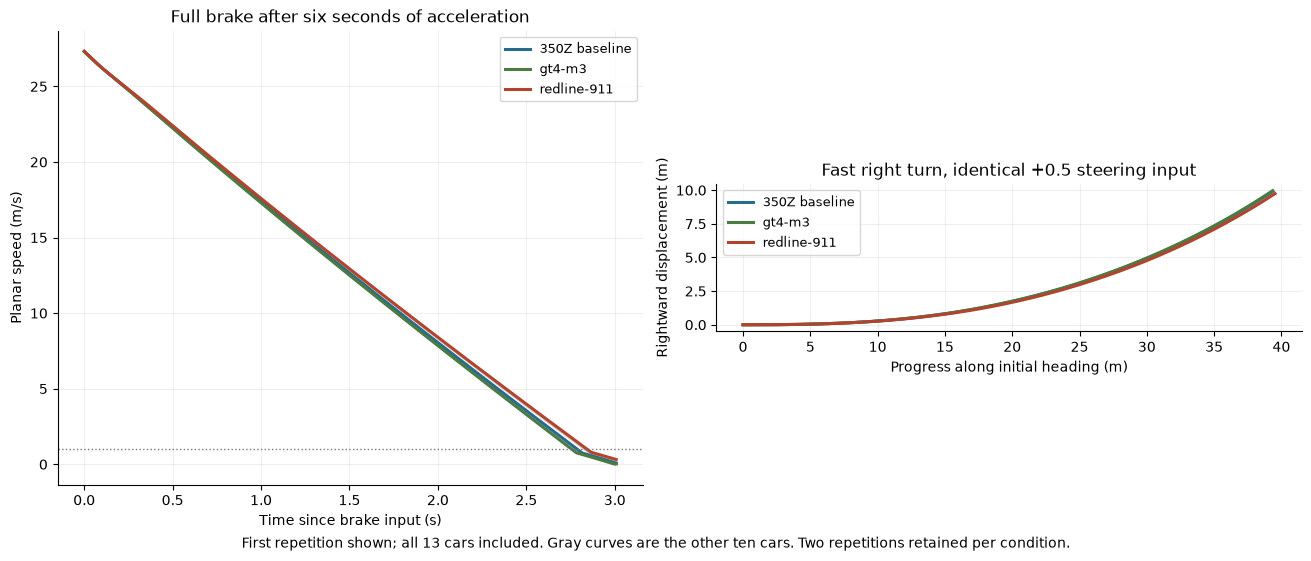

In [4]:
fig,axes=plt.subplots(1,2,figsize=(13,5.5),layout="constrained")
highlights={"350z":("#276b8e","350Z baseline"),worst_brake:("#b2442e",worst_brake),best_brake:("#4b7b43",best_brake)}
for run in sorted(runs,key=lambda r:r["car"] in highlights):
    if run["repeat"]!=1 or run["case"] not in ["brake","fast-right"]:
        continue
    ready=run["ready_tick"]
    events=read_jsonl(ROOT/run["run"]/"events.jsonl")
    completed={e["tick"]-ready:e["fields"] for e in events if e["kind"]=="simulation.completed"}
    color,label=highlights.get(run["car"],("#cccccc",None))
    width=2.2 if label else .8
    if run["case"]=="brake":
        ticks=range(959,1321)
        speed=[math.hypot(completed[t]["linear_velocity"][0],completed[t]["linear_velocity"][2]) for t in ticks]
        axes[0].plot([(t-959)/120 for t in ticks],speed,color=color,lw=width,label=label)
    else:
        ticks=range(959,1140)
        origin=completed[959]["position"]
        axes[1].plot([completed[t]["position"][0]-origin[0] for t in ticks],
                     [completed[t]["position"][2]-origin[2] for t in ticks],color=color,lw=width,label=label)
axes[0].axhline(1,color="#777777",ls=":",lw=1)
axes[0].set(title="Full brake after six seconds of acceleration",xlabel="Time since brake input (s)",ylabel="Planar speed (m/s)")
axes[1].set(title="Fast right turn, identical +0.5 steering input",xlabel="Progress along initial heading (m)",ylabel="Rightward displacement (m)")
axes[1].set_aspect("equal",adjustable="box")
for ax in axes:
    ax.grid(alpha=.2)
    ax.legend(fontsize=9)
fig.supxlabel("First repetition shown; all 13 cars included. Gray curves are the other ten cars. Two repetitions retained per condition.",fontsize=10)
fig.savefig(OUT/"traces.png",dpi=150)
plt.show()

### 5. Exact comparison and reliability

In [5]:
header="| Car | Brake m | Brake s | Low turn ° L/R | Fast turn ° L/R | Max slip ° | Four contacts | Unexpected resets |"
lines=[header,"|---|---:|---:|---:|---:|---:|---:|---:|"]
for car in order:
    b=by[car,"brake"]
    low="/".join(f"{by[car,c]['turn_deg']:.2f}" for c in ["turn-left","turn-right"])
    fast="/".join(f"{by[car,c]['turn_deg']:.2f}" for c in ["fast-left","fast-right"])
    slip=max(by[car,c]["peak_slip_deg"] for c in ["turn-left","turn-right","fast-left","fast-right"])
    support=min(by[car,c]["four_contact_pct"] for c in ["brake","turn-left","turn-right","fast-left","fast-right"])
    resets=sum(r["unexpected_resets"] for r in runs if r["car"]==car)
    lines.append(f"| {car} | {b['near_stop_m']:.3f} | {b['near_stop_s']:.3f} | {low} | {fast} | {slip:.2f} | {support:.1f}% | {resets} |")
display(Markdown("\n".join(lines)))
print("Minimum verified obstacle clearance:",min(r["course_clearance_m"] for r in runs),"m")
print("Largest recovery speed at +1 s:",max(r.get("recovery_1s_mps",0) for r in runs),"m/s")
print("Largest difference between repeats:",max(r["near_stop_m_range"][1]-r["near_stop_m_range"][0] for r in rows if r["case"]=="brake"),"m braking distance")

| Car | Brake m | Brake s | Low turn ° L/R | Fast turn ° L/R | Max slip ° | Four contacts | Unexpected resets |
|---|---:|---:|---:|---:|---:|---:|---:|
| redline-911 | 39.281 | 2.850 | 75.21/75.21 | 46.74/46.74 | 18.94 | 100.0% | 0 |
| mc3-supra | 39.074 | 2.833 | 74.96/74.96 | 46.98/46.98 | 18.89 | 100.0% | 0 |
| gt-rx7 | 39.021 | 2.825 | 75.29/75.29 | 46.65/46.65 | 18.62 | 100.0% | 0 |
| gt-viper | 39.010 | 2.825 | 76.53/76.53 | 47.57/47.57 | 19.41 | 100.0% | 0 |
| fr2-cobra | 38.606 | 2.800 | 77.07/77.07 | 47.79/47.78 | 19.47 | 100.0% | 0 |
| mc3-skyline | 38.551 | 2.792 | 76.08/76.08 | 47.67/47.67 | 19.28 | 100.0% | 0 |
| 350z | 38.501 | 2.792 | 75.83/75.83 | 47.33/47.33 | 18.93 | 100.0% | 0 |
| mcla-evo | 38.473 | 2.792 | 75.82/75.80 | 47.34/47.33 | 18.98 | 100.0% | 0 |
| redline-gt500 | 38.412 | 2.783 | 76.15/76.15 | 47.57/47.57 | 19.07 | 100.0% | 0 |
| gt4-nsx | 38.412 | 2.783 | 77.29/77.29 | 47.77/47.77 | 19.39 | 100.0% | 0 |
| mcla-skyline | 38.355 | 2.783 | 75.89/75.89 | 47.55/47.55 | 19.15 | 100.0% | 0 |
| fr2-fr500 | 38.249 | 2.775 | 77.42/77.42 | 48.23/48.23 | 19.70 | 100.0% | 0 |
| gt4-m3 | 38.087 | 2.758 | 75.76/75.77 | 47.36/47.36 | 18.83 | 100.0% | 0 |

Minimum verified obstacle clearance: 2.4833088171041595 m
Largest recovery speed at +1 s: 2.066902879960261e-06 m/s
Largest difference between repeats: 0.0 m braking distance


## Takeaways and limits

Use the measured braking and steering-response extremes as regression cases. Ground support and unrequested resets do not distinguish cars in this protocol. Larger yaw and larger slip describe different properties: do not combine them into an undocumented overall score. Differences here are small and reproducible simulation differences, not player skill, real-car specifications or a proof that the largest-yaw car is most controllable.

The reset check proves requested upright/stopped recovery after these runs; it does not measure crash likelihood under untested inputs. Original model source archives are absent, so the source-preservation asset check cannot complete; all runs use the same hash-identified prepared assets. No visual/GPU acceptance is claimed.

To regenerate the raw experiment, build the existing CLI, then run `python3 tools/run_handling_study.py --output artifacts/handling-study-new --workers 4`. Run `python3 tools/analyze_handling_study.py artifacts/handling-study-new` to audit and derive metrics. The notebook reads the frozen local evidence and raw trace paths; retain both. Python notebook/plot dependencies are recorded in `python-requirements.txt`.